In [ ]:
#calculate daily price return and relative trading volume
#using previous 20 trading days

## Exercise E1. Boeing Data Analysis

In a brand new Jupyter notebook, repeat the same exercise for **Boeing** (Code "BA"), or feel free to go for a company of your choice. Use the same 1-year period.

- Calculate daily price return and relative trading volume using the previous 20 trading days. Apply the same log transformation and standardization.
- Fit K-means with K=2 and plot the output in 2D. Show the clusters and their centers.
- Compute the distance of each point from its nearest cluster center. Find the top 5 anomalous days and highlight them on the 2D plot and the volume time series.
- Print the dates, daily returns, relative volumes and anomaly scores for these days. What kind of trends do you see? Are the anomalies related to high volume, large price moves, or both? Explain your findings in a markdown block.

- Try to repeat the exercise by setting K=5 in K-means clustering. Keep the same feature data and scaling so that you can compare the results. **(Important Note: `transform` will now give 5 distances for each point. Take the smallest distance across all 5 centers.)**

- Plot the output for K=5 and find the top 5 anomalous days again. How many dates are also in the K=2 results? Does the ranking change? Explain why adding more cluster centers may change which points are considered anomalous.

Would selecting the top 5 points prove that there are exactly 5 true anomalies? Briefly explain your answer.

In [ ]:
# If these libraries are not installed, uncomment the following line and run it
# %pip install yfinance numpy pandas matplotlib scikit-learn

import yfinance
import numpy as np
from matplotlib import pyplot
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

yfinance.__version__

'0.2.66'

In [ ]:
start_date = '2025-03-10'
end_date = '2026-03-10'

# auto_adjust=True gives us adjusted prices. The end date is excluded.
data_df = yfinance.download('BA', start=start_date, end=end_date,
                           auto_adjust=True, multi_level_index=False)

if data_df.empty:
    raise ValueError("No data was downloaded. Check the ticker, dates and connection.")

data_df = data_df.sort_index()
print("\nShape of data", data_df.shape)

# Print a few lines
data_df.head()

[*********************100%***********************]  1 of 1 completed


Shape of data (251, 5)


,Close,High,Low,Open,Volume
Date,,,,,
2025-03-10,148.149994,150.389999,146.300003,150.029999,10204000
2025-03-11,154.059998,155.009995,145.449997,148.000000,10030500
2025-03-12,158.800003,159.539993,153.610001,157.000000,8706900
2025-03-13,159.320007,161.740005,157.250000,159.220001,5701600
2025-03-14,161.809998,162.320007,159.199997,160.919998,5215100


In [ ]:
feature_df = data_df[["Close", "Volume"]].dropna().copy()
feature_df["Daily Return"] = feature_df["Close"].pct_change(fill_method=None) * 100


previous_volume = feature_df["Volume"].shift(1).rolling(window=20).median()
feature_df["Relative Volume"] = feature_df["Volume"] / previous_volume

# We need positive volume ratios to calculate their log
feature_df = feature_df.replace([np.inf, -np.inf], np.nan)
feature_df = feature_df.dropna(subset=["Daily Return", "Relative Volume"])
feature_df = feature_df[feature_df["Relative Volume"] > 0].copy()
feature_df["Log Relative Volume"] = np.log(feature_df["Relative Volume"])

if len(feature_df) < 5:
    raise ValueError("Not enough usable days. Download a longer period of data.")

print("Shape of feature data", feature_df.shape)
feature_df[["Daily Return", "Relative Volume", "Log Relative Volume"]].head()

Shape of feature data (231, 5)


,Daily Return,Relative Volume,Log Relative Volume
Date,,,
2025-04-07,1.661911,2.399832,0.875399
2025-04-08,0.381679,1.852033,0.616284
2025-04-09,15.374136,2.138521,0.760114
2025-04-10,-3.295612,1.322616,0.279612
2025-04-11,0.848760,1.070305,0.067944


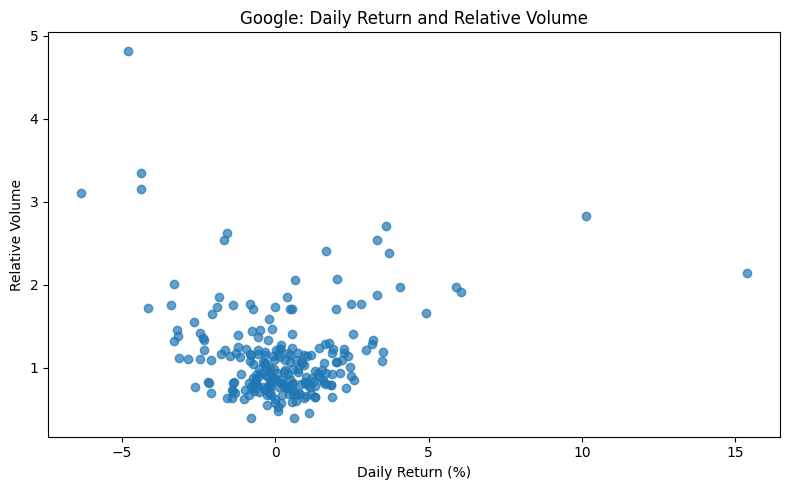

In [ ]:
pyplot.figure(figsize=(8, 5))
pyplot.scatter(feature_df["Daily Return"], feature_df["Relative Volume"], alpha=0.7)
pyplot.xlabel("Daily Return (%)")
pyplot.ylabel("Relative Volume")
pyplot.title("Boeing: Daily Return and Relative Volume")
pyplot.tight_layout()
pyplot.show()

In [ ]:
X = feature_df[["Daily Return", "Log Relative Volume"]].to_numpy()

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Find 2 clusters, use a fixed seed for reproducibility, and keep the best of 20 initializations
kmeans_model = KMeans(n_clusters=2, random_state=420, n_init=20)
kmeans_model.fit(X_scaled)


center = kmeans_model.cluster_centers_
print("Cluster centers in standardized feature space")
print(center)

Cluster centers in standardized feature space
[[-0.0610134  -0.66196779]
 [ 0.08428655  0.91447097]]


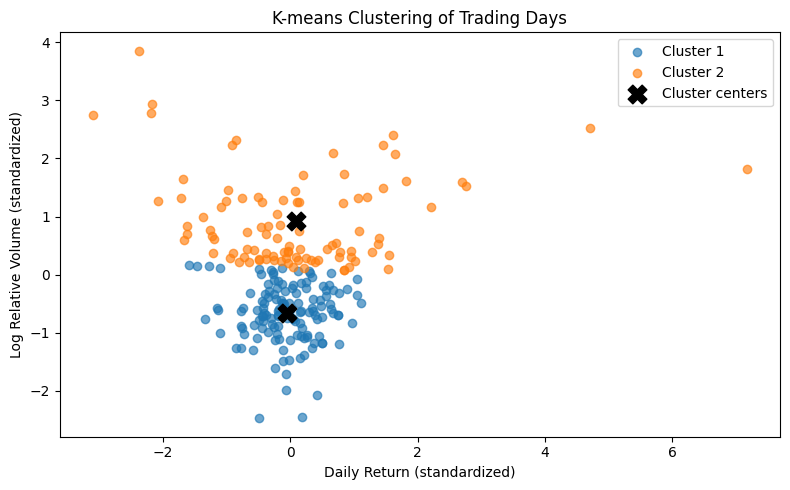

In [ ]:
pyplot.figure(figsize=(8, 5))

for cluster in range(kmeans_model.n_clusters):
    points = X_scaled[kmeans_model.labels_ == cluster]
    pyplot.scatter(points[:, 0], points[:, 1], alpha=0.65,
                   label="Cluster " + str(cluster + 1))

pyplot.scatter(center[:, 0], center[:, 1], color="black", marker="X",
               s=180, label="Cluster centers", zorder=3)
pyplot.xlabel("Daily Return (standardized)")
pyplot.ylabel("Log Relative Volume (standardized)")
pyplot.title("K-means Clustering of Trading Days")
pyplot.legend()
pyplot.tight_layout()
pyplot.show()

In [ ]:
# transform gives the distance of each point from every cluster center
# Keep the distance to the nearest center for each point
all_distances = kmeans_model.transform(X_scaled)
feature_df["Anomaly Score"] = all_distances.min(axis=1)
feature_df["Cluster"] = kmeans_model.labels_

# Take the top 5 points as anomaly candidates
# These are the same days in both the 2D plot and the volume plot below
top_5 = feature_df.nlargest(5, "Anomaly Score")

print("Top 5 anomalous trading days")
top_5[["Daily Return", "Relative Volume", "Anomaly Score"]]

Top 5 anomalous trading days


,Daily Return,Relative Volume,Anomaly Score
Date,,,
2025-04-09,15.374136,2.138521,7.147138
2025-12-02,10.146947,2.832709,4.883028
2025-06-12,-4.789720,4.818305,3.836047
2025-10-30,-6.320817,3.106720,3.682328
2025-10-29,-4.365737,3.350416,3.038339


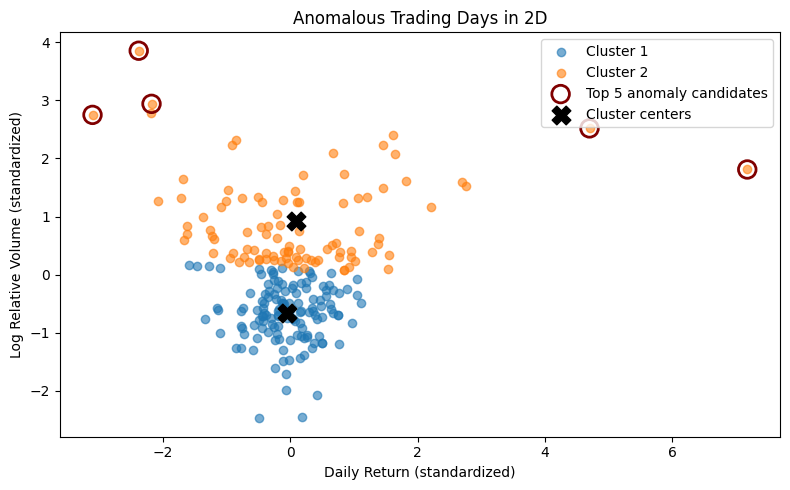

In [ ]:
# First plot the clusters in standardized feature space
pyplot.figure(figsize=(8, 5))

for cluster in range(kmeans_model.n_clusters):
    points = X_scaled[kmeans_model.labels_ == cluster]
    pyplot.scatter(points[:, 0], points[:, 1], alpha=0.6,
                   label="Cluster " + str(cluster + 1))

# Then add a layer showing the anomalous points
anomaly_positions = feature_df.index.get_indexer(top_5.index)
pyplot.scatter(X_scaled[anomaly_positions, 0], X_scaled[anomaly_positions, 1],
               facecolors="none", edgecolors="maroon", s=160,
               linewidths=2, label="Top 5 anomaly candidates", zorder=4)

pyplot.scatter(center[:, 0], center[:, 1], color="black", marker="X",
               s=180, label="Cluster centers", zorder=3)
pyplot.xlabel("Daily Return (standardized)")
pyplot.ylabel("Log Relative Volume (standardized)")
pyplot.title("Anomalous Trading Days in 2D")
pyplot.legend()
pyplot.tight_layout()
pyplot.show()

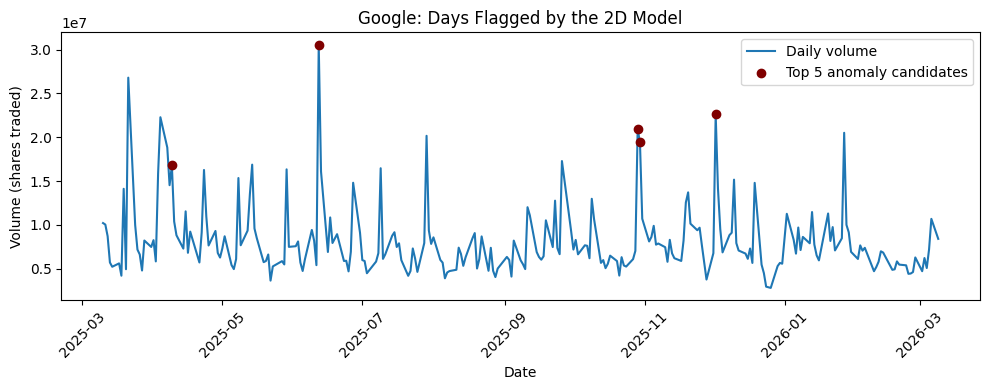

In [ ]:
pyplot.figure(figsize=(10, 4))
pyplot.plot(data_df.index, data_df["Volume"], label="Daily volume")
pyplot.scatter(top_5.index, top_5["Volume"], color="maroon",
               label="Top 5 anomaly candidates", zorder=3)
pyplot.xlabel("Date")
pyplot.ylabel("Volume (shares traded)")
pyplot.title("Google: Days Flagged by the 2D Model")
pyplot.xticks(rotation=45)
pyplot.legend()
pyplot.tight_layout()
pyplot.show()

### Findings and Analysis (K=2)

The anomalies are due to extreme price movements (very positive or very negative) and significantly higher trading volumes than the rolling median from the previous 20-day window. This matches up with standard financial market events where once a major company releases news, large price flucations occur along with a surge in liquidity/trading activity.

In [ ]:
# Fit KMeans with K=5
kmeans_model_k5 = KMeans(n_clusters=5, random_state=420, n_init=20)
kmeans_model_k5.fit(X_scaled)
centers_k5 = kmeans_model_k5.cluster_centers_

# Calculate distances to all 5 centers, and find the minimum distance for each point
all_distances_k5 = kmeans_model_k5.transform(X_scaled)
feature_df["Anomaly Score K5"] = all_distances_k5.min(axis=1)
feature_df["Cluster K5"] = kmeans_model_k5.labels_

# Identify top 5 anomalies for K=5
top_5_k5 = feature_df.nlargest(5, "Anomaly Score K5")

print("Top 5 anomalous trading days (K=5):")
display(top_5_k5[["Daily Return", "Relative Volume", "Anomaly Score K5"]])

Top 5 anomalous trading days (K=5):


,Daily Return,Relative Volume,Anomaly Score K5
Date,,,
2025-06-12,-4.789720,4.818305,2.680182
2025-10-30,-6.320817,3.106720,2.181313
2025-10-29,-4.365737,3.350416,1.759201
2025-12-26,-0.788413,0.389888,1.649735
2025-07-29,-4.369528,3.152484,1.622439


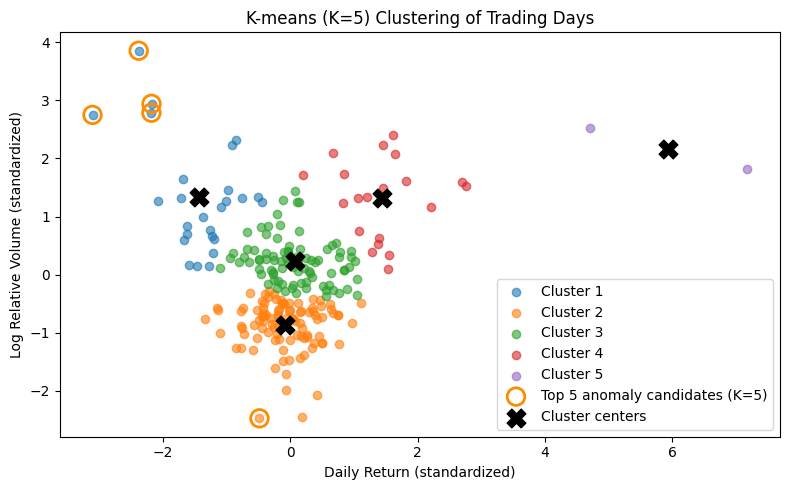

In [ ]:
# 2D Plot for K=5
pyplot.figure(figsize=(8, 5))

for cluster in range(5):
    points = X_scaled[kmeans_model_k5.labels_ == cluster]
    pyplot.scatter(points[:, 0], points[:, 1], alpha=0.6,
                   label=f"Cluster {cluster + 1}")

# Highlight K=5 Anomalies
anomaly_positions_k5 = feature_df.index.get_indexer(top_5_k5.index)
pyplot.scatter(X_scaled[anomaly_positions_k5, 0], X_scaled[anomaly_positions_k5, 1],
               facecolors="none", edgecolors="darkorange", s=160,
               linewidths=2, label="Top 5 anomaly candidates (K=5)", zorder=4)

pyplot.scatter(centers_k5[:, 0], centers_k5[:, 1], color="black", marker="X",
               s=180, label="Cluster centers", zorder=3)

pyplot.xlabel("Daily Return (standardized)")
pyplot.ylabel("Log Relative Volume (standardized)")
pyplot.title("K-means (K=5) Clustering of Trading Days")
pyplot.legend()
pyplot.tight_layout()
pyplot.show()

In [ ]:
pyplot.figure(figsize=(10, 4))
pyplot.plot(data_df.index, data_df["Volume"], label="Daily volume")
pyplot.scatter(top_5_k5.index, top_5_k5["Volume"], color="darkorange",
               label="Top 5 anomaly candidates (K=5)", zorder=3)
pyplot.xlabel("Date")
pyplot.ylabel("Volume (shares traded)")
pyplot.title("Boeing: Days Flagged by the 2D Model (K=5)")
pyplot.xticks(rotation=45)
pyplot.legend()
pyplot.tight_layout()
pyplot.show()

Comparing both models, we find that three of the top five anomalous trading days overlap because they represent the most extreme combinations of high volume and price swings. The ranking changed because adding more cluster centers (K=5) placed a new center near previous outliers, lowering their individual anomaly distances to their closest group center. Finally, choosing the top five points does not prove there are exactly five validated anomalies, as this is an subjective threshold applied to a variety of distance-based anomaly scores rather than a confirmed classification.